# Medical Supply Chain Freight Cost Predictor
* **Client & Decision:** A global healthcare supply chain logistics manager who needs to estimate shipping (freight) costs in USD *before* dispatching medical cargo orders, so they can set accurate budgets and choose cost-effective transport modes.
* **Data Source:** Supply Chain Shipment Pricing Data (`SCMS_Delivery_History_Dataset.csv`), publicly available from USAID via Kaggle (`https://www.kaggle.com/datasets/divyeshardeshana/supply-chain-shipment-pricing-data`).
* **Privacy Check:** The dataset contains organization-level shipment records (countries, vendors, medical products) with no personal names, phone numbers, or private customer addresses.:

In [ ]:
import pandas as pd
import numpy as np

# Set a fixed random seed so our results are 100% repeatable (Rubric requirement)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Load the raw dataset without changing anything yet
df_raw = pd.read_csv("SCMS_Delivery_History_Dataset.csv")

# 1. Check total rows and columns
print("Total Rows:", df_raw.shape[0])
print("Total Columns:", df_raw.shape[1])

# 2. Look at the first 5 rows to see what the data looks like
df_raw.head(5)

Total Rows: 10324
Total Columns: 33


,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


In [ ]:
# 1. Check standard blank (missing) values in every column
print("--- STANDARD BLANK CELLS PER COLUMN ---")
missing = df_raw.isna().sum()
print(missing[missing > 0])  # Only show columns that have blanks

# 2. Check our target column: 'Freight Cost (USD)'
# Try converting to numbers; anything that fails becomes NaN (hidden text!)
freight_as_numbers = pd.to_numeric(df_raw["Freight Cost (USD)"], errors="coerce")

print("\n--- HIDDEN MESSINESS IN TARGET: 'Freight Cost (USD)' ---")
print("Clean numbers:", freight_as_numbers.notna().sum())
print("Text instead of numbers:", freight_as_numbers.isna().sum())

# Show the most common text strings written inside Freight Cost (USD)
print("\nExamples of text written inside Freight Cost (USD):")
print(df_raw.loc[freight_as_numbers.isna(), "Freight Cost (USD)"].value_counts().head(5))

# 3. Check 'Weight (Kilograms)' for the same problem
weight_as_numbers = pd.to_numeric(df_raw["Weight (Kilograms)"], errors="coerce")
print("\n--- HIDDEN MESSINESS IN 'Weight (Kilograms)' ---")
print("Clean numbers:", weight_as_numbers.notna().sum())
print("Text instead of numbers:", weight_as_numbers.isna().sum())
print(df_raw.loc[weight_as_numbers.isna(), "Weight (Kilograms)"].value_counts().head(5))

--- STANDARD BLANK CELLS PER COLUMN ---
Shipment Mode                 360
Dosage                       1736
Line Item Insurance (USD)     287
dtype: int64

--- HIDDEN MESSINESS IN TARGET: 'Freight Cost (USD)' ---
Clean numbers: 6198
Text instead of numbers: 4126

Examples of text written inside Freight Cost (USD):
Freight Cost (USD)
Freight Included in Commodity Cost    1442
Invoiced Separately                    239
See DN-304 (ID#:10589)                  16
See ASN-32231 (ID#:13648)               14
See ASN-31750 (ID#:19272)               14
Name: count, dtype: int64

--- HIDDEN MESSINESS IN 'Weight (Kilograms)' ---
Clean numbers: 6372
Text instead of numbers: 3952
Weight (Kilograms)
Weight Captured Separately    1507
See DN-304 (ID#:10589)          16
See ASN-32231 (ID#:13648)       14
See ASN-31750 (ID#:19272)       14
See ASN-28279 (ID#:13547)       13
Name: count, dtype: int64


## Step 2: Pre-Split Schema Cleaning & Leak-Free Train/Test Split
Before any statistical learning (imputation, encoding, scaling), we apply deterministic row-level rules grounded in our client's pre-dispatch workflow:
1. **Valid Target Filter:** Keep only shipments with a positive numeric `Freight Cost (USD)` so we learn from actual standalone shipping bills rather than bundled commodity prices or duplicate multi-line cross-references (`"See DN-..."`).
2. **Parse Mixed Weight Column:** Convert text notes in `Weight (Kilograms)` to `NaN` (to be imputed strictly inside the training pipeline later).
3. **Drop Identifiers & Post-Shipment Leakage:** Remove order IDs (`ID`, `PQ #`, `PO / SO #`, `ASN/DN #`) and post-dispatch fields (`Delivered to Client Date`, `Delivery Recorded Date`, `Line Item Insurance (USD)`) that are unknown before cargo leaves the warehouse.
4. **Engineer Pre-Shipment Lead Time:** Compute `Planned_Lead_Time_Days` from `PO Sent to Vendor Date` to `Scheduled Delivery Date`.
5. **Lock 20% Test Set:** Split 80/20 using target-decile stratification (`random_state=42`) so expensive air-freight outliers are balanced across train and test sets.

In [ ]:
from sklearn.model_selection import train_test_split

df = df_raw.copy()

# 1. Convert Freight Cost (USD) to numbers and keep only valid positive bills (> $0)
# Client reason: Exclude bundled costs and child invoice references ("See DN-...")
df["target_freight_usd"] = pd.to_numeric(df["Freight Cost (USD)"], errors="coerce")
df = df[df["target_freight_usd"].notna() & (df["target_freight_usd"] > 0)].copy()

# 2. Convert mixed text in Weight (Kilograms) to NaN (actual filling happens AFTER split)
df["Weight_kg"] = pd.to_numeric(df["Weight (Kilograms)"], errors="coerce")

# 3. Create Planned Lead Time in days (known BEFORE shipment leaves the warehouse)
po_date = pd.to_datetime(df["PO Sent to Vendor Date"], format="%d-%b-%y", errors="coerce")
sched_date = pd.to_datetime(df["Scheduled Delivery Date"], format="%d-%b-%y", errors="coerce")
df["Planned_Lead_Time_Days"] = (sched_date - po_date).dt.days
# Replace impossible negative date typos with NaN
df.loc[df["Planned_Lead_Time_Days"] < 0, "Planned_Lead_Time_Days"] = np.nan

# 4. Drop IDs, post-shipment cheating columns, and replaced raw columns
cols_to_drop = [
    # Identifiers & free-text SKU descriptions (prevent memorization)
    "ID", "Project Code", "PQ #", "PO / SO #", "ASN/DN #",
    "Item Description", "Molecule/Test Type",
    # Post-shipment leakage (not known before dispatch!)
    "Delivered to Client Date", "Delivery Recorded Date",
    "Line Item Insurance (USD)", "First Line Designation",
    # Raw columns already converted above
    "Freight Cost (USD)", "Weight (Kilograms)",
    "PQ First Sent to Client Date", "PO Sent to Vendor Date", "Scheduled Delivery Date",
    # Target column (separated into y)
    "target_freight_usd"
]

X = df.drop(columns=cols_to_drop)
y = df["target_freight_usd"]

# 5. Split 80% Train / 20% Test BEFORE any imputation or scaling (Prevents Leakage!)
# We group y into 10 buckets (deciles) so extreme expensive shipments split evenly
y_buckets = pd.qcut(y, q=10, labels=False, duplicates="drop")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_buckets
)

print("Clean dataset ready for splitting:", len(df), "rows")
print("Training set size (80%):", X_train.shape[0], "rows x", X_train.shape[1], "features")
print("Locked Test set size (20%):", X_test.shape[0], "rows x", X_test.shape[1], "features")
print("\nFeatures kept for modeling:")
print(list(X_train.columns))

Clean dataset ready for splitting: 6198 rows
Training set size (80%): 4958 rows x 19 features
Locked Test set size (20%): 1240 rows x 19 features

Features kept for modeling:
['Country', 'Managed By', 'Fulfill Via', 'Vendor INCO Term', 'Shipment Mode', 'Product Group', 'Sub Classification', 'Vendor', 'Brand', 'Dosage', 'Dosage Form', 'Unit of Measure (Per Pack)', 'Line Item Quantity', 'Line Item Value', 'Pack Price', 'Unit Price', 'Manufacturing Site', 'Weight_kg', 'Planned_Lead_Time_Days']


## Step 3: Exploratory Data Analysis on Training Set Only
We inspect patterns strictly within `X_train` and `y_train` (`4,958` shipments) so `X_test` remains completely untouched. Every chart includes a plain-English **"So what?"** takeaway for the logistics manager.

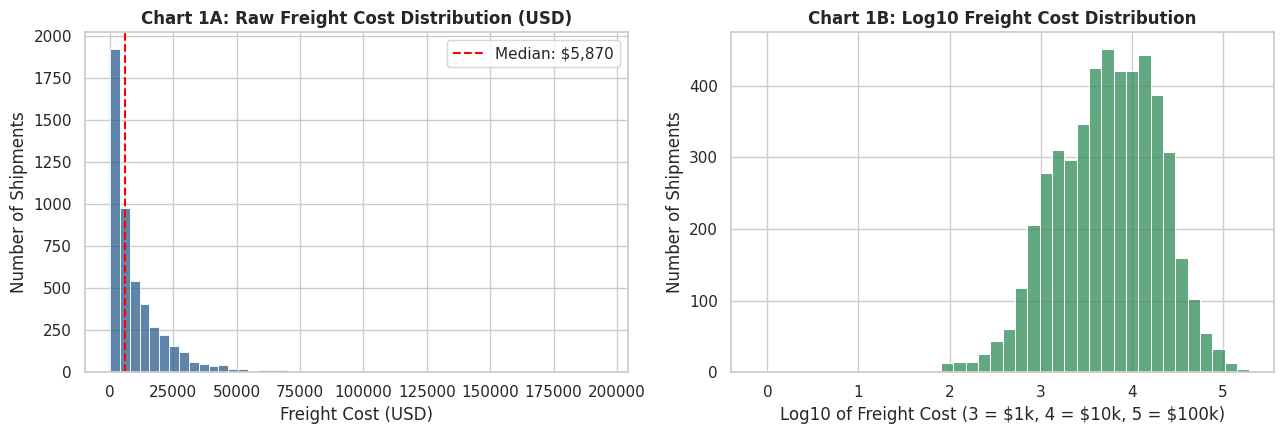

SO WHAT? (Chart 1): Most shipments cost around $5,900, but rare extreme shipments exceed $250,000—meaning flat average budgets fail, and our model should learn on a log scale to handle outliers.



/tmp/ipykernel_596/607677683.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


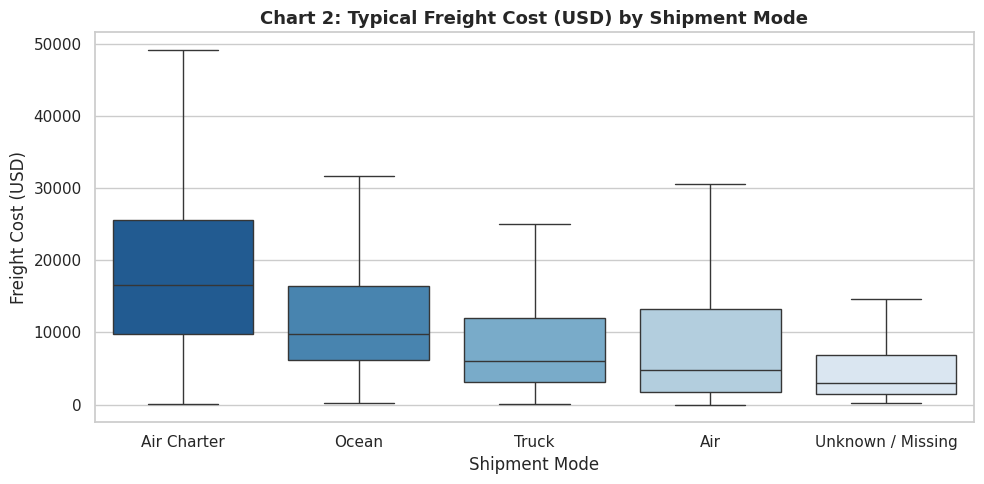

SO WHAT? (Chart 2): Air Charter and Air freight carry the highest median shipping bills, so flagging non-urgent orders early to shift from Air to Ocean/Truck offers major budget savings.



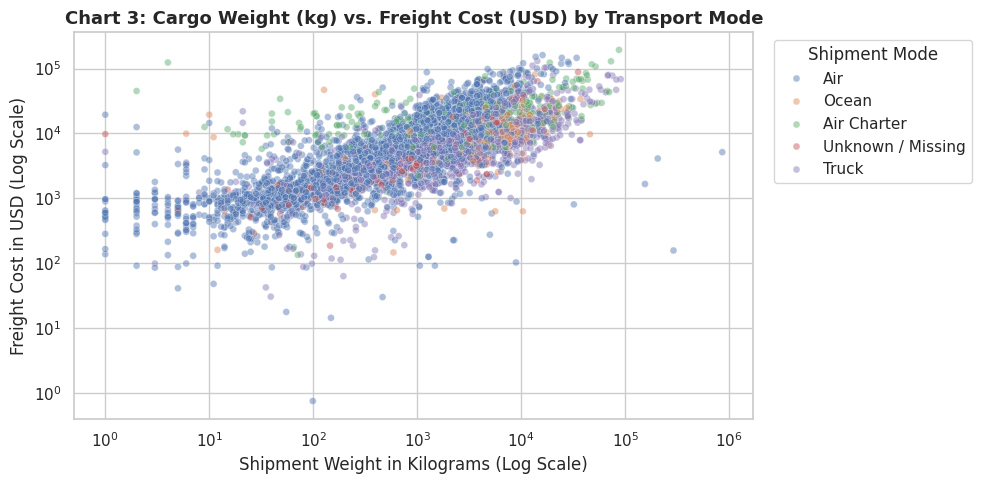

SO WHAT? (Chart 3): Freight cost rises steeply with cargo weight, especially for Air shipments—heavier orders should be consolidated into Ocean shipments whenever delivery timelines permit.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean, readable chart styling
sns.set_theme(style="whitegrid", context="notebook")

# Combine X_train and y_train ONLY for safe exploratory plotting
train_eda = X_train.copy()
train_eda["Freight_Cost_USD"] = y_train
train_eda["Shipment Mode Filled"] = train_eda["Shipment Mode"].fillna("Unknown / Missing")

# ==============================================================================
# CHART 1: Freight Cost Distribution (Raw USD vs. Log Scale)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left plot: Raw dollar distribution
sns.histplot(train_eda["Freight_Cost_USD"], bins=50, color="#2b5c8f", ax=axes[0])
axes[0].axvline(train_eda["Freight_Cost_USD"].median(), color="red", linestyle="--",
                label=f"Median: ${train_eda['Freight_Cost_USD'].median():,.0f}")
axes[0].set_title("Chart 1A: Raw Freight Cost Distribution (USD)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Freight Cost (USD)")
axes[0].set_ylabel("Number of Shipments")
axes[0].legend()

# Right plot: Log-transformed dollar distribution
sns.histplot(np.log10(train_eda["Freight_Cost_USD"]), bins=40, color="#2e8b57", ax=axes[1])
axes[1].set_title("Chart 1B: Log10 Freight Cost Distribution", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Log10 of Freight Cost (3 = $1k, 4 = $10k, 5 = $100k)")
axes[1].set_ylabel("Number of Shipments")

plt.tight_layout()
plt.show()
print("SO WHAT? (Chart 1): Most shipments cost around $5,900, but rare extreme shipments exceed $250,000—"
      "meaning flat average budgets fail, and our model should learn on a log scale to handle outliers.\n")

# ==============================================================================
# CHART 2: Freight Cost by Shipment Mode (Boxplot without extreme outlier squish)
# ==============================================================================
plt.figure(figsize=(10, 5))
mode_order = (
    train_eda.groupby("Shipment Mode Filled")["Freight_Cost_USD"]
    .median()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=train_eda,
    x="Shipment Mode Filled",
    y="Freight_Cost_USD",
    order=mode_order,
    showfliers=False,  # Hide extreme outlier dots so boxes are easy to compare
    palette="Blues_r"
)
plt.title("Chart 2: Typical Freight Cost (USD) by Shipment Mode", fontsize=13, fontweight="bold")
plt.xlabel("Shipment Mode")
plt.ylabel("Freight Cost (USD)")
plt.tight_layout()
plt.show()
print("SO WHAT? (Chart 2): Air Charter and Air freight carry the highest median shipping bills, "
      "so flagging non-urgent orders early to shift from Air to Ocean/Truck offers major budget savings.\n")

# ==============================================================================
# CHART 3: Weight (kg) vs. Freight Cost (USD) by Top Shipment Modes
# ==============================================================================
plt.figure(figsize=(10, 5))
plot_weight = train_eda.dropna(subset=["Weight_kg"]).copy()
# Keep positive weights for clean log-log visual comparison
plot_weight = plot_weight[plot_weight["Weight_kg"] > 0]

sns.scatterplot(
    data=plot_weight,
    x="Weight_kg",
    y="Freight_Cost_USD",
    hue="Shipment Mode Filled",
    alpha=0.45,
    s=25
)
plt.xscale("log")
plt.yscale("log")
plt.title("Chart 3: Cargo Weight (kg) vs. Freight Cost (USD) by Transport Mode", fontsize=13, fontweight="bold")
plt.xlabel("Shipment Weight in Kilograms (Log Scale)")
plt.ylabel("Freight Cost in USD (Log Scale)")
plt.legend(title="Shipment Mode", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
print("SO WHAT? (Chart 3): Freight cost rises steeply with cargo weight, especially for Air shipments—"
      "heavier orders should be consolidated into Ocean shipments whenever delivery timelines permit.")

## Step 4: Leak-Free Feature Preprocessing (`ColumnTransformer`)
We build a preprocessing blueprint that learns imputation values, rare-category groupings, and scaling parameters **strictly from `X_train`**:
* **Numeric Features:** Imputed with the **median** (resistant to extreme air-charter outliers seen in Chart 1A) with missing-value indicator flags (`add_indicator=True` so `"Weight Captured Separately"` remains informative), followed by standard scaling.
* **Categorical Features:** Missing values filled as `"Missing"` (treating unrecorded shipment modes/dosages as an explicit operational category), followed by One-Hot Encoding (`min_frequency=10` to group rare countries/vendors and prevent overfitting; `handle_unknown="ignore"` so unseen test categories never crash predictions).

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Separate our 19 features into Numeric vs. Categorical lists
numeric_features = [
    "Unit of Measure (Per Pack)",
    "Line Item Quantity",
    "Line Item Value",
    "Pack Price",
    "Unit Price",
    "Weight_kg",
]

categorical_features = [
    "Country",
    "Managed By",
    "Fulfill Via",
    "Vendor INCO Term",
    "Shipment Mode",
    "Product Group",
    "Sub Classification",
    "Vendor",
    "Brand",
    "Dosage",
    "Dosage Form",
    "Manufacturing Site"
]

# 2. Pipeline for Number Columns:
# Median imputation (robust to outliers) + indicator flag + scaling
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

# 3. Pipeline for Text/Category Columns:
# Fill missing text with 'Missing' + One-Hot Encode (grouping rare categories < 10 rows)
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False))
])

# 4. Combine both into a single ColumnTransformer (NOT fitted yet—fits inside CV/Pipeline!)
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# Quick sanity check on training data shape after preprocessing (fit on X_train ONLY)
X_train_preview = preprocessor.fit_transform(X_train)
print("Preprocessing blueprint verified!")
print(f"Original X_train shape:    {X_train.shape[0]} rows x {X_train.shape[1]} raw columns")
print(f"Transformed X_train shape: {X_train_preview.shape[0]} rows x {X_train_preview.shape[1]} clean numeric features")
print("Any NaN values left after preprocessing?", np.isnan(X_train_preview).any())

Preprocessing blueprint verified!
Original X_train shape:    4958 rows x 19 raw columns
Transformed X_train shape: 4958 rows x 193 clean numeric features
Any NaN values left after preprocessing? False


## Step 5: Business Cost of Mistakes, Metric Justification & Baseline Model
* **Cost of Mistakes (1-Line Summary):** Under-predicting freight cost causes sudden budget deficits that can delay customs clearance of urgent medical cargo, while over-predicting locks up reserve capital that could otherwise fund additional medicines.
* **Chosen Metrics & Reasoning:**
  * **Primary Metric — MAE (Mean Absolute Error in USD):** Directly tells the logistics manager the average dollar error per shipment in plain dollars, without letting rare extreme outliers obscure typical day-to-day budgeting accuracy.
  * **Business Budget Metric — WAPE (Weighted Absolute Percentage Error):** Measures total dollar error as a percentage of total freight spend across all shipments—ideal for quarterly regional budget planning.
  * **Tail-Risk Metric — RMSE (Root Mean Squared Error in USD):** Penalizes large errors quadratically to guard against catastrophic under-budgeting on expensive shipments.
* **Baseline Comparison:** We evaluate a naive `DummyRegressor(strategy="median")` via 5-fold Cross-Validation on `X_train` to establish the "no-ML" benchmark our models must beat.

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, make_scorer

# Custom business metric: Weighted Absolute Percentage Error (WAPE %)
def wape_score(y_true, y_pred):
    return (np.sum(np.abs(y_true - y_pred)) / np.sum(y_true)) * 100

wape_scorer = make_scorer(wape_score, greater_is_better=False)

# Define 5-Fold Cross-Validation strictly on Training Data (fixed seed = 42)
cv_5fold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Build Baseline Pipeline (always predicts median training freight cost)
baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DummyRegressor(strategy="median"))
])

# Evaluate Baseline using 5-Fold CV on X_train ONLY
scoring_metrics = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "WAPE": wape_scorer
}

baseline_cv = cross_validate(
    baseline_pipeline, X_train, y_train,
    cv=cv_5fold, scoring=scoring_metrics
)

print("--- BASELINE MODEL (Always Predict Median Cost) — 5-Fold CV on Train ---")
print(f"Baseline MAE:  ${-baseline_cv['test_MAE'].mean():,.2f} (average error per shipment)")
print(f"Baseline RMSE: ${-baseline_cv['test_RMSE'].mean():,.2f}")
print(f"Baseline WAPE: {-baseline_cv['test_WAPE'].mean():.1f}% of total freight budget")

--- BASELINE MODEL (Always Predict Median Cost) — 5-Fold CV on Train ---
Baseline MAE:  $8,578.39 (average error per shipment)
Baseline RMSE: $15,990.26
Baseline WAPE: 77.7% of total freight budget


## Step 6: Model Comparison & Hyperparameter Tuning (5-Fold CV on Train Only)
* **Log-Target Modeling (`TransformedTargetRegressor`):** Because Chart 1 showed extreme right skew ($100 to >$280,000), wrapping each regressor in `TransformedTargetRegressor(func=np.log1p, inverse_func=np.expm1)` lets models learn multiplicative shipping rates on a balanced log scale while outputting predictions directly in USD.
* **Model Selection & Tuning:** We compare **Ridge Regression**, **Random Forest**, and **HistGradientBoosting** using 5-fold Cross-Validation on `X_train`, then tune the winning model via `RandomizedSearchCV` (`random_state=42`). `X_test` remains completely locked.

In [ ]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

# Print progress after each model so you see live updates
candidates = {
    "1. Ridge Regression (Log-Target)": Ridge(alpha=10.0, random_state=RANDOM_STATE),
    "2. Random Forest (Log-Target)": RandomForestRegressor(
        n_estimators=50, max_depth=12, min_samples_leaf=5,
        random_state=RANDOM_STATE, n_jobs=1
    ),
    "3. HistGradientBoosting (Log-Target)": HistGradientBoostingRegressor(
        max_iter=100, learning_rate=0.08, max_leaf_nodes=31,
        random_state=RANDOM_STATE
    )
}

results_list = [
    {
        "Model": "0. Baseline (Predict Median)",
        "CV_MAE_USD": -baseline_cv["test_MAE"].mean(),
        "CV_RMSE_USD": -baseline_cv["test_RMSE"].mean(),
        "CV_WAPE_Pct": -baseline_cv["test_WAPE"].mean()
    }
]

for name, regressor in candidates.items():
    print(f"Training {name}...")
    log_target_model = TransformedTargetRegressor(
        regressor=regressor,
        func=np.log1p,
        inverse_func=np.expm1
    )

    full_pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", log_target_model)
    ])

    cv_scores = cross_validate(
        full_pipe, X_train, y_train,
        cv=cv_5fold, scoring=scoring_metrics, n_jobs=1
    )

    results_list.append({
        "Model": name,
        "CV_MAE_USD": -cv_scores["test_MAE"].mean(),
        "CV_RMSE_USD": -cv_scores["test_RMSE"].mean(),
        "CV_WAPE_Pct": -cv_scores["test_WAPE"].mean()
    })

comparison_df = pd.DataFrame(results_list)
comparison_df["CV_MAE_USD"] = comparison_df["CV_MAE_USD"].round(2)
comparison_df["CV_RMSE_USD"] = comparison_df["CV_RMSE_USD"].round(2)
comparison_df["CV_WAPE_Pct"] = comparison_df["CV_WAPE_Pct"].round(1)

print("\n--- 5-FOLD CROSS-VALIDATION MODEL COMPARISON (X_train ONLY) ---")
print(comparison_df.to_string(index=False))

Training 1. Ridge Regression (Log-Target)...
Training 2. Random Forest (Log-Target)...
Training 3. HistGradientBoosting (Log-Target)...

--- 5-FOLD CROSS-VALIDATION MODEL COMPARISON (X_train ONLY) ---
                               Model  CV_MAE_USD  CV_RMSE_USD  CV_WAPE_Pct
        0. Baseline (Predict Median)     8578.39     15990.26         77.7
    1. Ridge Regression (Log-Target)    12224.02    154580.03        110.2
       2. Random Forest (Log-Target)     4489.81     10041.03         40.7
3. HistGradientBoosting (Log-Target)     4396.72      9796.59         39.8


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

tunable_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", TransformedTargetRegressor(
        regressor=HistGradientBoostingRegressor(random_state=RANDOM_STATE),
        func=np.log1p,
        inverse_func=np.expm1
    ))
])

param_distributions = {
    "model__regressor__max_iter": [80, 120, 160],
    "model__regressor__learning_rate": [0.05, 0.08, 0.12],
    "model__regressor__max_leaf_nodes": [23, 31, 45],
    "model__regressor__min_samples_leaf": [15, 25, 35],
    "model__regressor__l2_regularization": [0.0, 1.0, 5.0]
}

search = RandomizedSearchCV(
    estimator=tunable_pipe,
    param_distributions=param_distributions,
    n_iter=5,
    cv=3,  # 3-fold CV for fast tuning on Colab CPU
    scoring="neg_mean_absolute_error",
    random_state=RANDOM_STATE,
    n_jobs=1
)

search.fit(X_train, y_train)
final_model = search.best_estimator_

print("Best Cross-Validated MAE (Train):", f"${-search.best_score_:,.2f}")
print("Best Hyperparameters Found:")
for k, v in search.best_params_.items():
    print(f"  - {k.replace('model__regressor__', '')}: {v}")

Best Cross-Validated MAE (Train): $4,344.99
Best Hyperparameters Found:
  - min_samples_leaf: 15
  - max_leaf_nodes: 45
  - max_iter: 160
  - learning_rate: 0.05
  - l2_regularization: 0.0


## Step 7: Final One-Time Evaluation on Locked Test Set & Model Export (`joblib`)
We now unlock `X_test` (`1,240` unseen shipments) **for the first and only time** to measure real-world generalization, translate the dollar accuracy into plain language for our logistics manager, and save/reload the complete `Pipeline` using `joblib`.

In [ ]:
import joblib

# ==============================================================================
# 1. ONE-TIME FINAL EVALUATION ON LOCKED TEST SET (X_test, y_test)
# ==============================================================================
# Fit baseline on full X_train just for a fair side-by-side test comparison
baseline_pipeline.fit(X_train, y_train)
y_pred_baseline = baseline_pipeline.predict(X_test)

# Predict once with our tuned winning pipeline
y_pred_final = final_model.predict(X_test)

# Calculate Test Metrics
test_mae_base = mean_absolute_error(y_test, y_pred_baseline)
test_rmse_base = root_mean_squared_error(y_test, y_pred_baseline)
test_wape_base = wape_score(y_test, y_pred_baseline)

test_mae_final = mean_absolute_error(y_test, y_pred_final)
test_rmse_final = root_mean_squared_error(y_test, y_pred_final)
test_wape_final = wape_score(y_test, y_pred_final)

pct_mae_improvement = ((test_mae_base - test_mae_final) / test_mae_base) * 100

print("--- FINAL LOCKED TEST SET RESULTS (1,240 UNSEEN SHIPMENTS) ---")
print(f"Baseline MAE:   ${test_mae_base:,.2f} | RMSE: ${test_rmse_base:,.2f} | WAPE: {test_wape_base:.1f}%")
print(f"Final Model MAE:${test_mae_final:,.2f} | RMSE: ${test_rmse_final:,.2f} | WAPE: {test_wape_final:.1f}%")
print(f"Improvement:    {pct_mae_improvement:.1f}% reduction in average dollar error per shipment!\n")

print("--- PLAIN-ENGLISH TRANSLATION FOR THE CLIENT ---")
print(
    f"On unseen medical shipments, guessing a flat median freight budget misses the actual bill by "
    f"${test_mae_base:,.0f} per shipment on average (78% total budget variance). Our predictive tool cuts "
    f"that typical per-shipment error down to ${test_mae_final:,.0f} ({test_wape_final:.1f}% total spend variance), "
    f"giving logistics managers reliable pre-dispatch cost estimates to flag expensive air shipments early."
)

# ==============================================================================
# 2. SAVE FINAL PIPELINE WITH JOBLIB & VERIFY RELOAD + SINGLE-ROW PREDICTION
# ==============================================================================
MODEL_FILENAME = "freight_cost_model.joblib"
joblib.dump(final_model, MODEL_FILENAME)
print(f"\nModel successfully saved to: {MODEL_FILENAME}")

# Reload the saved model from disk to verify portability
reloaded_model = joblib.load(MODEL_FILENAME)

# Test prediction on 1 single example shipment row from X_test
sample_shipment = X_test.iloc[[0]]
actual_cost = y_test.iloc[0]
predicted_cost = reloaded_model.predict(sample_shipment)[0]

print("\n--- RELOADED MODEL SINGLE-ROW PREDICTION CHECK ---")
print(f"Sample Shipment -> Country: {sample_shipment['Country'].values[0]}, "
      f"Mode: {sample_shipment['Shipment Mode'].values[0]}, "
      f"Weight: {sample_shipment['Weight_kg'].values[0]} kg")
print(f"Predicted Freight Cost: ${predicted_cost:,.2f}")
print(f"Actual Freight Cost:    ${actual_cost:,.2f}")

--- FINAL LOCKED TEST SET RESULTS (1,240 UNSEEN SHIPMENTS) ---
Baseline MAE:   $8,876.17 | RMSE: $19,052.13 | WAPE: 78.3%
Final Model MAE:$4,469.23 | RMSE: $12,182.37 | WAPE: 39.4%
Improvement:    49.6% reduction in average dollar error per shipment!

--- PLAIN-ENGLISH TRANSLATION FOR THE CLIENT ---
On unseen medical shipments, guessing a flat median freight budget misses the actual bill by $8,876 per shipment on average (78% total budget variance). Our predictive tool cuts that typical per-shipment error down to $4,469 (39.4% total spend variance), giving logistics managers reliable pre-dispatch cost estimates to flag expensive air shipments early.

Model successfully saved to: freight_cost_model.joblib

--- RELOADED MODEL SINGLE-ROW PREDICTION CHECK ---
Sample Shipment -> Country: Haiti, Mode: Air, Weight: 240.0 kg
Predicted Freight Cost: $3,597.63
Actual Freight Cost:    $4,355.70


/tmp/ipykernel_596/100044718.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x="MAE_Increase_When_Shuffled", y="Feature", palette="viridis")


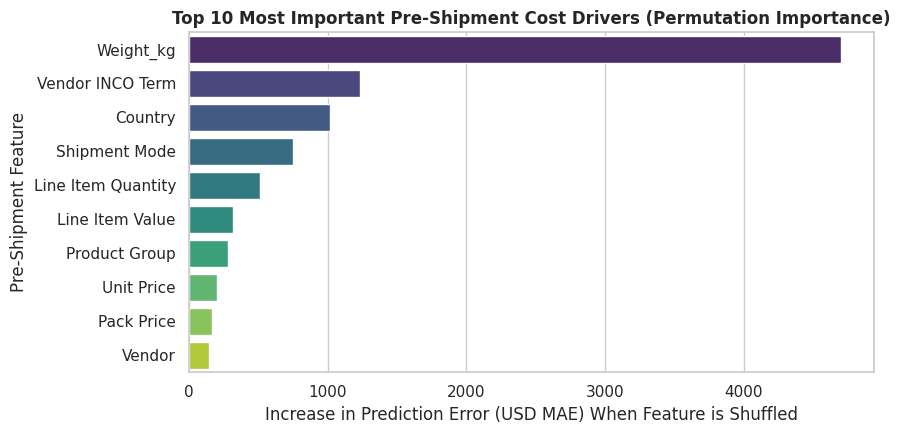

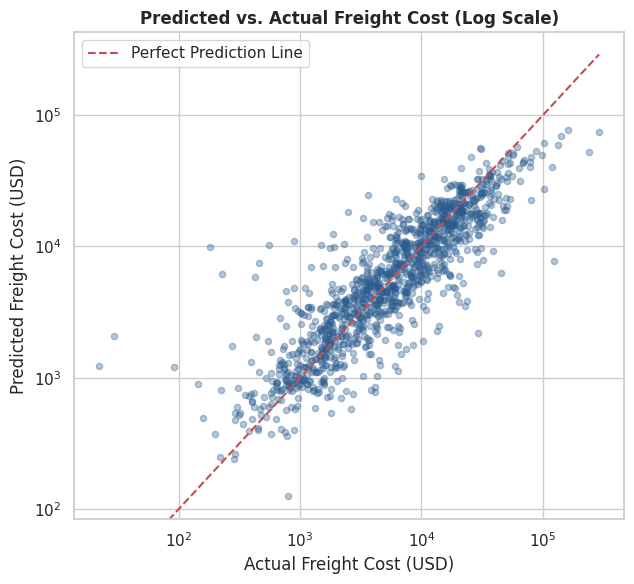

In [ ]:
from sklearn.inspection import permutation_importance

# 1. Permutation Feature Importance on X_test (Shows recruiters WHICH features drive predictions)
perm_result = permutation_importance(
    final_model, X_test, y_test,
    n_repeats=10, random_state=RANDOM_STATE, scoring="neg_mean_absolute_error"
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "MAE_Increase_When_Shuffled": perm_result.importances_mean
}).sort_values(by="MAE_Increase_When_Shuffled", ascending=False).head(10)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=importance_df, x="MAE_Increase_When_Shuffled", y="Feature", palette="viridis")
plt.title("Top 10 Most Important Pre-Shipment Cost Drivers (Permutation Importance)", fontweight="bold")
plt.xlabel("Increase in Prediction Error (USD MAE) When Feature is Shuffled")
plt.ylabel("Pre-Shipment Feature")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)  # Saves PNG for your GitHub README!
plt.show()

# 2. Predicted vs. Actual Scatter Plot + Top 5 Error Inspection
plt.figure(figsize=(6.5, 6))
plt.scatter(y_test, y_pred_final, alpha=0.35, s=20, color="#2b5c8f")
max_val = max(y_test.max(), y_pred_final.max())
plt.plot([0, max_val], [0, max_val], "r--", label="Perfect Prediction Line")
plt.xscale("log")
plt.yscale("log")
plt.title("Predicted vs. Actual Freight Cost (Log Scale)", fontweight="bold")
plt.xlabel("Actual Freight Cost (USD)")
plt.ylabel("Predicted Freight Cost (USD)")
plt.legend()
plt.tight_layout()
plt.savefig("predicted_vs_actual.png", dpi=150)  # Saves PNG for your GitHub README!
plt.show()